In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [40]:
data=np.load('Processed_data.npz')
X_train_scaled=data['X_train']
X_test_scaled=data['X_test']
y_train=data['y_train']
y_test=data['y_test']

In [1]:
def perceptron(X,y,epochs=1000,learning_rate=0.1):
   X=np.asarray(X,dtype=float)
   y=np.asarray(y).reshape(-1)
   
   if X.ndim!=2:
      raise ValueError("X must be a 2-D array")

   if X.shape[0]!=y.shape[0]:
      raise ValueError("X and y must have equal sample counts")

   if X.shape[0]==0 or X.shape[1]==0:
      raise ValueError('X cannot be empty')

   if not np.isfinite(X).all():
      raise ValueError("X contains NaN or infinite values")

   if not np.isfinite(y).all():
         raise ValueError("y contains NaN or infinite values")

   if not np.isin(y,[0,1]).all():
      raise ValueError('y must contain only 0 and 1')

   if epochs<=0:
      raise ValueError('Epochs cannot be negative')

   if learning_rate<=0:
      raise ValueError('learning rate must be positive')

   #Adding bias column
   X=np.insert(X,0,1,axis=1)

   #Initializing parameters with zeros
   weights=np.zeros(X.shape[1])
   rng=np.random.default_rng(0)

   #Tracking accuracy and mistakes
   accuracy_history=[]
   error_history=[]

   for i in range(epochs):
      indices=rng.permutation(X.shape[0])
      errors=0
      for j in indices:
         z=np.dot(X[j],weights)
         y_hat=step(z)
         weights=weights+learning_rate*(y[j]-y_hat)*X[j]

         if y_hat!=y[j]:
            errors+=1

      y_pred=step(np.dot(X,weights))
      accuracy=np.mean(y_pred==y)
      accuracy_history.append(accuracy)

      error_history.append(errors)
   return weights[0],weights[1:],accuracy_history,error_history

    

In [2]:
def step(z):
    return np.where(z>0,1,0)

In [ ]:

plt.figure(figsize=(8,5))

plt.plot(accuracy_history)

plt.xlabel("Epochs")
plt.ylabel("Training Accuracy")
plt.title("Perceptron Learning Curve")

plt.grid()
plt.show()

NameError: name 'plt' is not defined

In [92]:
print(accuracy_history[:50])


[np.float64(0.9626373626373627), np.float64(0.9802197802197802), np.float64(0.9868131868131869), np.float64(0.9538461538461539), np.float64(0.9802197802197802), np.float64(0.9560439560439561), np.float64(0.9824175824175824), np.float64(0.9758241758241758), np.float64(0.9714285714285714), np.float64(0.9736263736263736), np.float64(0.9824175824175824), np.float64(0.978021978021978), np.float64(0.9692307692307692), np.float64(0.978021978021978), np.float64(0.9692307692307692), np.float64(0.9824175824175824), np.float64(0.9802197802197802), np.float64(0.9846153846153847), np.float64(0.9802197802197802), np.float64(0.967032967032967), np.float64(0.9824175824175824), np.float64(0.9802197802197802), np.float64(0.9802197802197802), np.float64(0.9868131868131869), np.float64(0.989010989010989), np.float64(0.9824175824175824), np.float64(0.9802197802197802), np.float64(0.9824175824175824), np.float64(0.9736263736263736), np.float64(0.989010989010989), np.float64(0.989010989010989), np.float64(0.

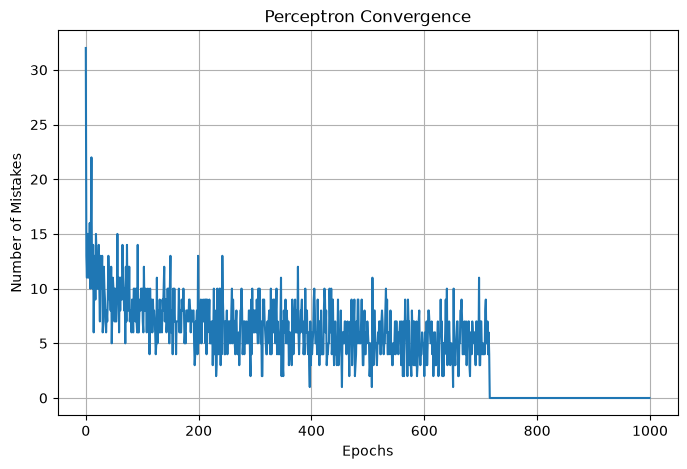

In [93]:
plt.figure(figsize=(8,5))

plt.plot(error_history)

plt.xlabel("Epochs")
plt.ylabel("Number of Mistakes")
plt.title("Perceptron Convergence")

plt.grid()
plt.show()